In [21]:
!pip install -q langchain langchain-groq

In [22]:
import os
from google.colab import userdata
os.environ["GROQ_API_KEY"] = userdata.get("GROQ_API_KEY")   # LangChain reads it from here

from langchain_groq import ChatGroq
llm = ChatGroq(model="openai/gpt-oss-120b", temperature=0.3)

In [23]:
from typing import Literal
from pydantic import BaseModel, Field

class Intent(BaseModel):
    intent: Literal["order", "faq", "other"] = Field(
        description="order = wants to buy or book; faq = asks about prices, timings or policies; other = anything else")

classifier = llm.with_structured_output(Intent)        # Day 4: structured output

def handle(message: str) -> str:
    intent = classifier.invoke(message).intent        # 1. sort
    if intent == "order":                             # 2. route
        return take_order(message)
    elif intent == "faq":
        return answer_faq(message)
    else:
        return "I can help with cakes, orders and our policies. What would you like?"

In [24]:
from typing_extensions import TypedDict

class BakeryState(TypedDict):
    message: str     # what the customer wrote
    intent: str      # filled in by the classify step
    reply: str       # filled in by whichever path handles it

In [25]:
from langgraph.graph import StateGraph, START, END

def classify(state: BakeryState) -> dict:
    return {"intent": classifier.invoke(state["message"]).intent}

def answer_faq(state: BakeryState) -> dict:
    return {"reply": "…answer from search_faq…"}

builder = StateGraph(BakeryState)          # 1. a new graph that uses our state
builder.add_node("classify", classify)     # 2. add the steps
builder.add_node("faq", answer_faq)
builder.add_edge(START, "classify")        # 3. connect them
builder.add_edge("classify", "faq")
builder.add_edge("faq", END)
graph = builder.compile()                  # 4. compile before running

result = graph.invoke({"message": "Do you deliver?"})
print(result["reply"])

…answer from search_faq…


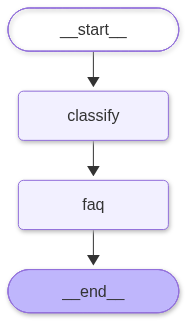

{'classify': {'intent': 'faq'}}
{'faq': {'reply': '…answer from search_faq…'}}


In [32]:
from IPython.display import Image, display
from langchain_core.messages import SystemMessage, HumanMessage
from langchain_groq import ChatGroq
from langgraph.graph import StateGraph, START, END

# Use an available Groq model that supports Structured Outputs
llm = ChatGroq(model="openai/gpt-oss-120b", temperature=0)
classifier = llm.with_structured_output(Intent)

def classify(state: BakeryState) -> dict:
    messages = [
        SystemMessage(
            content=(
                "Classify the customer's message into one of the intent categories "
                "('order', 'faq', or 'other'). Do not answer the question."
            )
        ),
        HumanMessage(content=state["message"]),
    ]
    result = classifier.invoke(messages)
    return {"intent": result.intent}

builder = StateGraph(BakeryState)
builder.add_node("classify", classify)
builder.add_node("faq", answer_faq)
builder.add_edge(START, "classify")
builder.add_edge("classify", "faq")
builder.add_edge("faq", END)
graph = builder.compile()

# 1. Render the graph diagram
display(Image(graph.get_graph().draw_mermaid_png()))

# 2. Stream updates
for step in graph.stream({"message": "Do you deliver?"}, stream_mode="updates"):
    print(step)

In [33]:
import os, requests
r = requests.get(
    "https://api.groq.com/openai/v1/models",
    headers={"Authorization": f"Bearer {os.environ['GROQ_API_KEY']}"},
)
print([m["id"] for m in r.json().get("data", [])])

['meta-llama/llama-prompt-guard-2-86m', 'whisper-large-v3-turbo', 'openai/gpt-oss-120b', 'meta-llama/llama-prompt-guard-2-22m', 'openai/gpt-oss-20b', 'openai/gpt-oss-safeguard-20b', 'whisper-large-v3', 'qwen/qwen3.8-27b', 'canopylabs/orpheus-v1-english', 'canopylabs/orpheus-arabic-saudi', 'allam-2-7b']


In [34]:
!pip install -q langgraph

In [35]:
import os
from google.colab import userdata

# Retrieve the Groq API key from Colab Secrets (add it to the Secrets tab on the left sidebar)
try:
    os.environ["GROQ_API_KEY"] = userdata.get("GROQ_API_KEY")
except Exception:
    print("Please add GROQ_API_KEY to your Colab Secrets.")

# Initialize the LLM with a valid Groq model
llm = ChatGroq(
    model="openai/gpt-oss-120b",
    temperature=0
)

In [36]:

from typing import Literal
from typing_extensions import TypedDict
from pydantic import BaseModel, Field
from langgraph.graph import StateGraph, START, END
from langchain.agents import create_agent

class BakeryState(TypedDict):
    message: str
    intent: str
    reply: str

class Intent(BaseModel):
    intent: Literal["order", "faq", "other"] = Field(
        description="order = wants to buy or book cakes; faq = asks about prices, timings or "
                    "policies; other = greetings or anything unrelated to the bakery")

classifier = llm.with_structured_output(Intent)

In [38]:
from langchain_core.tools import tool

@tool
def search_faq(query: str) -> str:
    """Search Sweet Crumbs Home Bakery policies, delivery, and general FAQs."""
    faqs = {
        "delivery": "We offer local delivery and pickup for pre-booked cakes.",
        "custom": "Custom cakes require at least 48 hours notice.",
        "allergens": "Our kitchen handles wheat, dairy, eggs, and nuts.",
    }
    q = query.lower()
    for key, answer in faqs.items():
        if key in q:
            return answer
    return "No matching FAQ policy found."

@tool
def get_price(item: str, quantity: int = 1) -> str:
    """Look up the price for a bakery item and calculate the total for a quantity."""
    menu = {
        "chocolate cake": 25.0,
        "red velvet cake": 28.0,
        "cupcakes": 3.0,
    }
    price = menu.get(item.lower())
    if price is None:
        return f"Item '{item}' not found on the price list."
    total = price * quantity
    return f"{quantity} x {item} = ${total:.2f} (${price:.2f} each)"

@tool
def is_open(day: str = "") -> str:
    """Check opening hours for Sweet Crumbs Home Bakery."""
    return "Sweet Crumbs Home Bakery is open Tuesday–Sunday, 9:00 AM to 7:00 PM (closed Mondays)."

@tool
def log_order(customer_name: str, item: str, quantity: int, pickup_date: str) -> str:
    """Save a confirmed cake order after collecting name, item, quantity, and pickup date."""
    return (
        f"Order logged for {customer_name}: {quantity} x {item} "
        f"for pickup on {pickup_date}."
    )

In [39]:
FAQ_PROMPT = """You answer questions for Sweet Crumbs Home Bakery.
Use get_price for prices, is_open for timings and search_faq for policies. Never guess.
If the answer isn't found, say "I'll check with the owner." Under 50 words."""

ORDER_PROMPT = """You take cake orders for Sweet Crumbs Home Bakery.
Use get_price for totals. Before log_order, make sure you have name, item, quantity and
pickup date; ask for anything missing. After saving, read the order back. Under 60 words."""

faq_agent = create_agent(model=llm, tools=[search_faq, get_price, is_open], system_prompt=FAQ_PROMPT)
order_agent = create_agent(model=llm, tools=[get_price, log_order], system_prompt=ORDER_PROMPT)

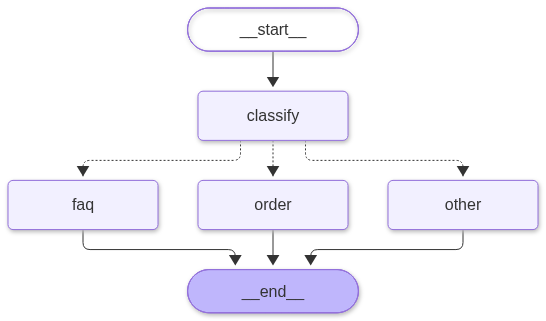

In [40]:
def classify(state: BakeryState) -> dict:
    return {"intent": classifier.invoke(state["message"]).intent}

def ask_agent(agent, message: str) -> str:
    result = agent.invoke({"messages": [{"role": "user", "content": message}]})
    return result["messages"][-1].content

def answer_faq(state: BakeryState) -> dict:
    return {"reply": ask_agent(faq_agent, state["message"])}

def take_order(state: BakeryState) -> dict:
    return {"reply": ask_agent(order_agent, state["message"])}

def other(state: BakeryState) -> dict:
    return {"reply": "Hello from Sweet Crumbs! I can help with cakes, prices, orders and our policies."}

def route(state: BakeryState) -> str:
    return state["intent"]

builder = StateGraph(BakeryState)
builder.add_node("classify", classify)
builder.add_node("faq", answer_faq)
builder.add_node("order", take_order)
builder.add_node("other", other)
builder.add_edge(START, "classify")
builder.add_conditional_edges("classify", route, {"order": "order", "faq": "faq", "other": "other"})
builder.add_edge("faq", END)
builder.add_edge("order", END)
builder.add_edge("other", END)
graph = builder.compile()

from IPython.display import Image, display
display(Image(graph.get_graph().draw_mermaid_png()))

In [41]:
tests = ["Do you deliver to my area?",
         "I'm Ravi, book 2 eggless plum cakes for 24 Dec",
         "Good morning!",
         "Is the plum cake nut-free?"]

for msg in tests:
    print("\nCustomer:", msg)
    for step in graph.stream({"message": msg}, stream_mode="updates"):
        print("  ", step)


Customer: Do you deliver to my area?
   {'classify': {'intent': 'faq'}}
   {'faq': {'reply': 'We offer local delivery (and pickup) for pre‑booked cakes. Let us know your address and we’ll confirm if it’s within our delivery area.'}}

Customer: I'm Ravi, book 2 eggless plum cakes for 24 Dec
   {'classify': {'intent': 'order'}}
   {'order': {'reply': 'Hi Ravi! I’ve got your name, 2 cakes, and a pickup on\u202f24\u202fDec. Could you tell me the exact menu name for the eggless plum cake (e.g., “Eggless Plum Cake” or another wording) so I can get the price and finish your order?'}}

Customer: Good morning!
   {'classify': {'intent': 'other'}}
   {'other': {'reply': 'Hello from Sweet Crumbs! I can help with cakes, prices, orders and our policies.'}}

Customer: Is the plum cake nut-free?
   {'classify': {'intent': 'faq'}}
   {'faq': {'reply': "I'll check with the owner."}}
